In [1]:
%pip install opencv-python pandas matplot

  Using cached matplot-0.1.9-py2.py3-none-any.whl.metadata (241 bytes)
  Using cached pyloco-0.0.139-py2.py3-none-any.whl.metadata (1.1 kB)
  Using cached ushlex-0.99.1.tar.gz (4.7 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached twine-7.0.0-py3-none-any.whl.metadata (3.5 kB)
  Using cached typing-3.7.4.3.tar.gz (78 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached SimpleWebSocketServer-0.1.2.tar.g


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import cv2
import os

# Caminho da pasta raiz com as imagens
input_dir = "resized-images_640_480"
# Caminho da pasta onde serão salvas as imagens redimensionadas
output_dir = "resized-images_100_75"

# Tamanho desejado (largura, altura)
new_size = (100, 75)

# Cria a pasta de saída se não existir
os.makedirs(output_dir, exist_ok=True)

# Iterar sobre todas as subpastas e arquivos
for root, dirs, files in os.walk(input_dir):
    for file in files:
        # Extensões de imagem aceitas
        if file.lower().endswith((".jpg")):
            # Caminho completo da imagem original
            input_path = os.path.join(root, file)

            # Lê a imagem
            img = cv2.imread(input_path)
            if img is None:
                print(f"Erro ao ler {input_path}")
                continue

            # Redimensiona
            resized = cv2.resize(img, new_size, interpolation=cv2.INTER_AREA)

            # Cria a pasta de saída correspondente
            relative_path = os.path.relpath(root, input_dir)
            save_dir = os.path.join(output_dir, relative_path)
            os.makedirs(save_dir, exist_ok=True)

            # Caminho de saída
            output_path = os.path.join(save_dir, file)

            # Salva a imagem
            cv2.imwrite(output_path, resized)

            #print(f"Imagem salva em {output_path}")


#### Testando os canais de uma imagem, como exemplo, e sua transformação para tom de cinza

In [6]:
import cv2
import matplotlib.pyplot as plt
import pandas as pd

def plot_image_channels(img_path):
    img = cv2.imread(img_path)  # lê em BGR
    #img = cv2.resize(img, (100, 75))    # garante 100x75

    # Converter para RGB (matplotlib trabalha com RGB)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # --- 2. Separar canais ---
    R = img_rgb[:, :, 0]
    G = img_rgb[:, :, 1]
    B = img_rgb[:, :, 2]

    # Converter para escala de cinza
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # --- 3. Exibir imagens lado a lado ---
    fig, axs = plt.subplots(1, 4, figsize=(12, 4))

    axs[0].imshow(R, cmap='Reds')
    axs[0].set_title("Canal R")
    axs[0].axis("off")

    axs[1].imshow(G, cmap='Greens')
    axs[1].set_title("Canal G")
    axs[1].axis("off")

    axs[2].imshow(B, cmap='Blues')
    axs[2].set_title("Canal B")
    axs[2].axis("off")

    axs[3].imshow(gray, cmap='gray')
    axs[3].set_title("Cinza")
    axs[3].axis("off")

    plt.tight_layout()
    plt.show()
    
    return gray

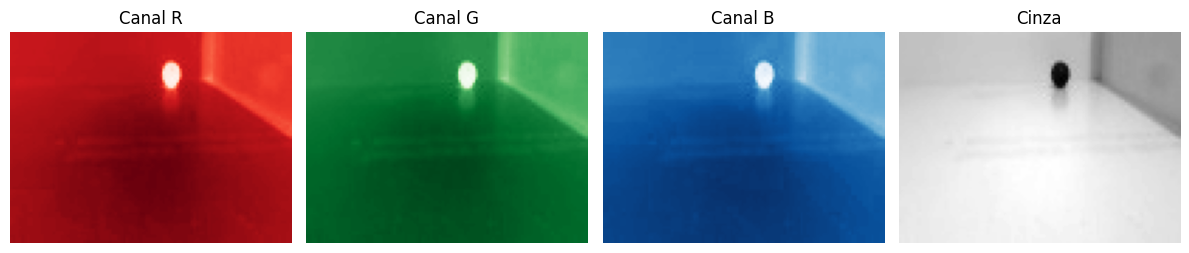

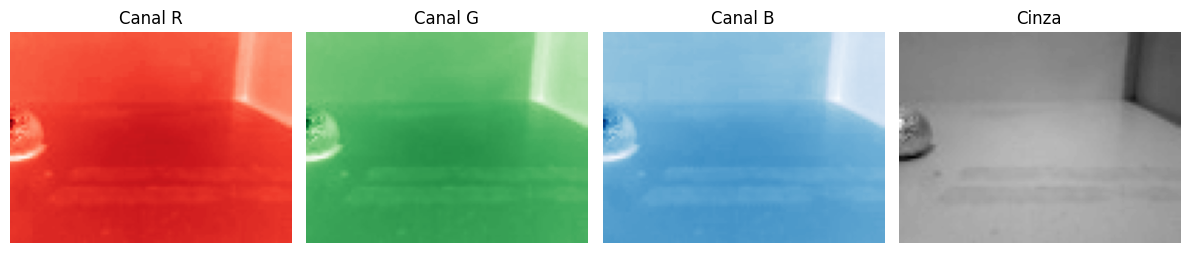

In [8]:
# --- 1. Ler a imagem ---
vitima_morta_sample = 'resized-images_100_75/ComVitimaMorta/20201029_095407.jpg'
img_grey_1 = plot_image_channels(vitima_morta_sample)
vitima_viva_sample = 'resized-images_100_75/ComVitimaViva/20201028_151111.jpg'
img_grey_2 = plot_image_channels(vitima_viva_sample)

#### Vamos iterar em cada pasta e criar o dataframe com as features

In [9]:
import glob
import os
# Caminho da pasta onde estão as imagens
folder_morta = "resized-images_100_75/ComVitimaMorta/"   # ajuste para o seu diretório

# Lista de arquivos .jpg
files = glob.glob(os.path.join(folder_morta, "*.jpg"))

# Lista para armazenar os vetores de cada imagem
data_list = []

for file in files:
    # --- 1. Ler a imagem ---
    img = cv2.imread(file)  # lê em BGR
    #img = cv2.resize(img, (640, 480))    # garante resolução compatível com treinamento

    # Converter para escala de cinza
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # --- 2. Flatten da imagem ---
    features = gray.flatten()

    # Adiciona ao dataset
    data_list.append(features)

# --- 3. Criar DataFrame ---
df_morta = pd.DataFrame(data_list)

print(f"Total de imagens lidas: {len(df_morta)}")
print(f"Formato do DataFrame: {df_morta.shape}")  # (n_imagens, 640x480)

Total de imagens lidas: 461
Formato do DataFrame: (461, 7500)


#### Adicionar RÓTULO 0 para Vítima MORTA

In [10]:
df_morta['y'] = 0

In [11]:
df_morta.head()

,0,1,2,3,4,5,6,7,8,9,...,7491,7492,7493,7494,7495,7496,7497,7498,7499,y
0,133,134,134,134,134,134,134,134,133,134,...,152,152,151,151,150,151,151,150,150,0
1,134,134,136,137,137,137,136,136,137,137,...,153,153,152,152,152,152,152,152,152,0
2,137,135,134,134,135,136,136,135,135,135,...,151,150,150,150,150,150,150,149,149,0
3,141,141,141,141,141,142,142,142,141,141,...,159,158,158,158,157,157,157,157,157,0
4,159,160,160,160,160,161,161,160,159,159,...,174,175,175,175,175,175,176,176,176,0


In [12]:
df_morta.shape

(461, 7501)

In [13]:
# Caminho da pasta onde estão as imagens
folder_viva = "resized-images_100_75/ComVitimaViva/"   # ajuste para o seu diretório

# Lista de arquivos .jpg
files = glob.glob(os.path.join(folder_viva, "*.jpg"))

# Lista para armazenar os vetores de cada imagem
data_list = []

for file in files:
    # --- 1. Ler a imagem ---
    img = cv2.imread(file)  # lê em BGR
    #img = cv2.resize(img, (100, 75))    # garante 100x75

    # Converter para escala de cinza
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # --- 2. Flatten da imagem ---
    features = gray.flatten()

    # Adiciona ao dataset
    data_list.append(features)

# --- 3. Criar DataFrame ---
df_viva = pd.DataFrame(data_list)

print(f"Total de imagens lidas: {len(df_viva)}")
print(f"Formato do DataFrame: {df_viva.shape}")  # (n_imagens, 7500)

Total de imagens lidas: 461
Formato do DataFrame: (461, 7500)


In [14]:
df_viva['y'] = 1

In [15]:
df_viva.shape

(461, 7501)

In [16]:
# Caminho da pasta onde estão as imagens
folder_sem = "resized-images_100_75/SemVitima/"   # ajuste para o seu diretório

# Lista de arquivos .jpg
files = glob.glob(os.path.join(folder_sem, "*.jpg"))

# Lista para armazenar os vetores de cada imagem
data_list = []

for file in files:
    # --- 1. Ler a imagem ---
    img = cv2.imread(file)  # lê em BGR
    #img = cv2.resize(img, (100, 75))    # garante 100x75

    # Converter para escala de cinza
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # --- 2. Flatten da imagem ---
    features = gray.flatten()

    # Adiciona ao dataset
    data_list.append(features)

# --- 3. Criar DataFrame ---
df_sem = pd.DataFrame(data_list)

print(f"Total de imagens lidas: {len(df_sem)}")
print(f"Formato do DataFrame: {df_sem.shape}")  # (n_imagens, 7500)

Total de imagens lidas: 462
Formato do DataFrame: (462, 7500)


In [17]:
df_sem['y'] = 2

In [6]:
#df_sem.shape

In [5]:
#df_sem.head()

#### Unido os três dataframes

In [18]:
df_final = pd.concat([df_morta, df_viva, df_sem], ignore_index=True)

In [19]:
df_final.to_csv('imageset_gray_100_75.csv', index=False)